In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import KFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.multiclass import OneVsRestClassifier
from sklearn.multioutput import MultiOutputClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, hamming_loss, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             multilabel_confusion_matrix)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

# File tanpa header -> header=None
train = pd.read_csv("zipcode_train.csv", header=None)
test = pd.read_csv("zipcode_test.csv", header=None)

# Peran kolom (inferensi dari data, ubah jika ada informasi lain)
LABEL_IDX = list(range(0, 7))       # kolom 0-6  = 7 label biner
FEATURE_IDX = list(range(7, 17))    # kolom 7-16 = 10 fitur

LABEL_COLS = [f"label_{i+1}" for i in range(len(LABEL_IDX))]
FEATURE_COLS = [f"fitur_{i+1}" for i in range(len(FEATURE_IDX))]
nama_baru = LABEL_COLS + FEATURE_COLS
train.columns = nama_baru
test.columns = nama_baru

print("Train:", train.shape, "| Test:", test.shape)
display(train.head())

Train: (3000, 17) | Test: (3000, 17)


,label_1,label_2,label_3,label_4,label_5,label_6,label_7,fitur_1,fitur_2,fitur_3,fitur_4,fitur_5,fitur_6,fitur_7,fitur_8,fitur_9,fitur_10
0,1,1,1,0,0,1,0,1,17.0,0.0,0.451613,0,0.793103,0.902439,0.812500,1.120370,1
1,1,0,0,1,1,1,1,0,0.0,0.0,0.000000,9,0.090900,0.739130,0.869565,6.000000,2
2,1,0,0,0,1,1,1,0,0.0,0.0,3.000000,0,4.421052,0.258823,1.636364,4.111111,3
3,1,1,0,0,0,0,0,0,0.0,0.0,0.739130,0,18.548390,1.022727,0.949152,0.346667,4
4,1,1,0,1,0,1,0,0,0.0,0.0,0.375000,1,0.000000,1.228261,1.333333,1.265625,5


In [2]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 17 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   label_1   3000 non-null   int64  
 1   label_2   3000 non-null   int64  
 2   label_3   3000 non-null   int64  
 3   label_4   3000 non-null   int64  
 4   label_5   3000 non-null   int64  
 5   label_6   3000 non-null   int64  
 6   label_7   3000 non-null   int64  
 7   fitur_1   3000 non-null   int64  
 8   fitur_2   3000 non-null   float64
 9   fitur_3   3000 non-null   float64
 10  fitur_4   3000 non-null   float64
 11  fitur_5   3000 non-null   int64  
 12  fitur_6   3000 non-null   float64
 13  fitur_7   3000 non-null   float64
 14  fitur_8   3000 non-null   float64
 15  fitur_9   3000 non-null   float64
 16  fitur_10  3000 non-null   int64  
dtypes: float64(7), int64(10)
memory usage: 398.6 KB


In [3]:
print("Missing value  train/test:", train.isna().sum().sum(), "/", test.isna().sum().sum())
print("Duplikat baris train/test:", train.duplicated().sum(), "/", test.duplicated().sum())
print("Baris yang sama di train dan test:", len(train.merge(test.drop_duplicates(), how="inner")))

ringkas = pd.DataFrame({"dtype": train.dtypes.astype(str), "nunique": train.nunique(),
                        "min": train.min(), "max": train.max(), "rata2": train.mean().round(3)})
display(ringkas)

# fitur_10 (kolom terakhir): apakah berulang 1..10 sesuai urutan baris?
pola = (train["fitur_10"].values == (np.arange(len(train)) % 10) + 1).all()
print("fitur_10 = urutan baris berulang 1..10 :", pola)
print(train["fitur_10"].value_counts().sort_index().to_dict())

Missing value  train/test: 0 / 0
Duplikat baris train/test: 0 / 7
Baris yang sama di train dan test: 1


,dtype,nunique,min,max,rata2
label_1,int64,2,0.0000,1.000000,0.887
label_2,int64,2,0.0000,1.000000,0.798
label_3,int64,2,0.0000,1.000000,0.445
label_4,int64,2,0.0000,1.000000,0.402
label_5,int64,2,0.0000,1.000000,0.114
label_6,int64,2,0.0000,1.000000,0.667
label_7,int64,2,0.0000,1.000000,0.219
fitur_1,int64,3,0.0000,2.000000,0.510
fitur_2,float64,48,0.0000,28.000000,6.233
fitur_3,float64,20,0.0000,27.500000,2.053


fitur_10 = urutan baris berulang 1..10 : True
{1: 300, 2: 300, 3: 300, 4: 300, 5: 300, 6: 300, 7: 300, 8: 300, 9: 300, 10: 300}


In [4]:
Y_train = train[LABEL_COLS].astype(int)
Y_test = test[LABEL_COLS].astype(int)

jumlah_label = Y_train.sum(axis=1)
kardinalitas = jumlah_label.mean()
densitas = kardinalitas / Y_train.shape[1]

print(f"Label cardinality : {kardinalitas:.3f}")
print(f"Label density     : {densitas:.3f}")
print(f"Baris tanpa label aktif: {(jumlah_label == 0).sum()}")
print(f"Baris dengan >1 label  : {(jumlah_label > 1).sum()} ({(jumlah_label > 1).mean()*100:.1f}%)")

kombinasi_train = set(map(tuple, Y_train.values))
kombinasi_test = set(map(tuple, Y_test.values))
print(f"Kombinasi unik: train={len(kombinasi_train)}, test={len(kombinasi_test)}, "
      f"di test tapi tidak di train={len(kombinasi_test - kombinasi_train)}")

per_label = pd.DataFrame({"positif_train": Y_train.sum(),
                          "persen_train": (Y_train.mean() * 100).round(1),
                          "persen_test": (Y_test.mean() * 100).round(1)})
display(per_label)

Label cardinality : 3.532
Label density     : 0.505
Baris tanpa label aktif: 3
Baris dengan >1 label  : 2836 (94.5%)
Kombinasi unik: train=61, test=57, di test tapi tidak di train=4


,positif_train,persen_train,persen_test
label_1,2661,88.7,87.8
label_2,2394,79.8,81.5
label_3,1335,44.5,43.2
label_4,1206,40.2,39.8
label_5,343,11.4,10.3
label_6,2000,66.7,66.1
label_7,658,21.9,20.7


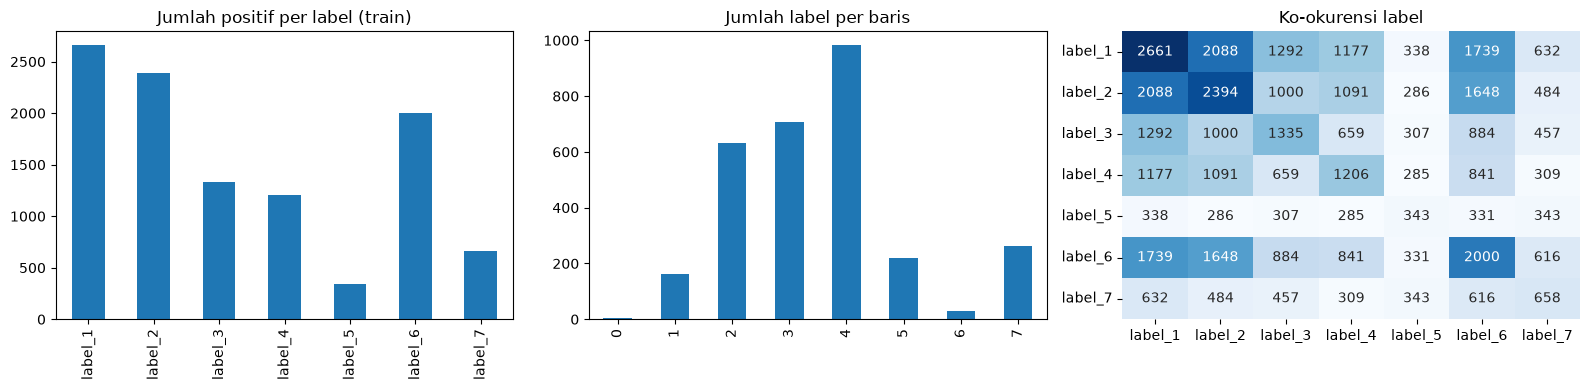

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
per_label["positif_train"].plot(kind="bar", ax=axes[0])
axes[0].set_title("Jumlah positif per label (train)")
jumlah_label.value_counts().sort_index().plot(kind="bar", ax=axes[1])
axes[1].set_title("Jumlah label per baris")
sns.heatmap(Y_train.T.dot(Y_train), annot=True, fmt="d", cmap="Blues", ax=axes[2], cbar=False)
axes[2].set_title("Ko-okurensi label")
plt.tight_layout()
plt.show()

In [6]:
cv_uji = KFold(n_splits=5, shuffle=True, random_state=0)
X_uji = train[FEATURE_COLS[:-1]].values     # tanpa fitur_10

hasil = {}
for c in LABEL_COLS:
    p = cross_val_predict(RandomForestClassifier(200, random_state=0, n_jobs=-1, min_samples_leaf=3),
                          X_uji, Y_train[c], cv=cv_uji, method="predict_proba")[:, 1]
    hasil[c] = roc_auc_score(Y_train[c], p)

display(pd.Series(hasil).round(3).to_frame("ROC-AUC (cross-validation)"))

,ROC-AUC (cross-validation)
label_1,0.958
label_2,0.835
label_3,0.872
label_4,0.986
label_5,0.980
label_6,0.944
label_7,0.977


In [7]:
X_train = train[FEATURE_COLS].values
X_test = test[FEATURE_COLS].values

models = {
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                                            random_state=42, n_jobs=-1),
    "Gradient Boosting": MultiOutputClassifier(HistGradientBoostingClassifier(random_state=42)),
    "KNN": Pipeline([("sc", StandardScaler()), ("clf", KNeighborsClassifier(n_neighbors=5))]),
    "Logistic Regression (balanced)": Pipeline([
        ("sc", StandardScaler()),
        ("clf", OneVsRestClassifier(LogisticRegression(max_iter=3000, class_weight="balanced")))]),
}

def hitung_metrik(Y_asli, Y_pred):
    return {
        "Subset accuracy": accuracy_score(Y_asli, Y_pred),
        "Hamming loss": hamming_loss(Y_asli, Y_pred),
        "F1 (micro)": f1_score(Y_asli, Y_pred, average="micro", zero_division=0),
        "F1 (macro)": f1_score(Y_asli, Y_pred, average="macro", zero_division=0),
        "F1 (samples)": f1_score(Y_asli, Y_pred, average="samples", zero_division=0),
    }

cv = KFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for nama, model in models.items():
    pred = cross_val_predict(model, X_train, Y_train.values, cv=cv)
    rows.append({"Model": nama, **hitung_metrik(Y_train.values, pred)})

hasil_cv = pd.DataFrame(rows).set_index("Model").round(4).sort_values("F1 (macro)", ascending=False)
display(hasil_cv)
print("Pembanding tebak semua 0 -> hamming loss:", round(hamming_loss(Y_train, np.zeros_like(Y_train)), 4))

,Subset accuracy,Hamming loss,F1 (micro),F1 (macro),F1 (samples)
Model,,,,,
Random Forest,0.5967,0.0761,0.9252,0.9119,0.9081
Gradient Boosting,0.5800,0.0777,0.9234,0.9094,0.9064
KNN,0.5533,0.0887,0.9130,0.8953,0.8950
Logistic Regression (balanced),0.3320,0.1610,0.8360,0.8137,0.7924


Pembanding tebak semua 0 -> hamming loss: 0.5046


In [8]:
def proba_matrix(model, X_):
    p = model.predict_proba(X_)
    if isinstance(p, list):
        return np.column_stack([a[:, 1] for a in p])
    return p

fitted, rows = {}, []
for nama, model in models.items():
    model.fit(X_train, Y_train.values)
    pred = model.predict(X_test)
    fitted[nama] = model
    rows.append({"Model": nama, **hitung_metrik(Y_test.values, pred),
                 "ROC-AUC (macro)": roc_auc_score(Y_test.values, proba_matrix(model, X_test), average="macro")})

hasil_test = pd.DataFrame(rows).set_index("Model").round(4).sort_values("F1 (macro)", ascending=False)
display(hasil_test)

,Subset accuracy,Hamming loss,F1 (micro),F1 (macro),F1 (samples),ROC-AUC (macro)
Model,,,,,,
Random Forest,0.5690,0.0798,0.9210,0.9051,0.9035,0.9474
Gradient Boosting,0.5567,0.0826,0.9183,0.9030,0.9013,0.9450
KNN,0.5283,0.0960,0.9052,0.8883,0.8834,0.9109
Logistic Regression (balanced),0.3180,0.1706,0.8252,0.7985,0.7769,0.8894


In [9]:
nama_terbaik = hasil_cv.index[0]            # dipilih berdasarkan cross-validation
terbaik = fitted[nama_terbaik]
pred = terbaik.predict(X_test)
skor = proba_matrix(terbaik, X_test)

print("Model terbaik (menurut CV):", nama_terbaik)
print(classification_report(Y_test.values, pred, target_names=LABEL_COLS, zero_division=0))

auc_label = {c: roc_auc_score(Y_test[c], skor[:, i]) for i, c in enumerate(LABEL_COLS)}
display(pd.Series(auc_label).round(3).to_frame("ROC-AUC"))

Model terbaik (menurut CV): Random Forest
              precision    recall  f1-score   support

     label_1       0.98      0.99      0.98      2634
     label_2       0.90      0.96      0.93      2444
     label_3       0.74      0.73      0.74      1295
     label_4       0.96      0.96      0.96      1193
     label_5       0.90      0.88      0.89       310
     label_6       0.91      0.95      0.93      1983
     label_7       0.91      0.90      0.90       622

   micro avg       0.91      0.93      0.92     10481
   macro avg       0.90      0.91      0.91     10481
weighted avg       0.91      0.93      0.92     10481
 samples avg       0.91      0.93      0.90     10481



,ROC-AUC
label_1,0.984
label_2,0.866
label_3,0.863
label_4,0.992
label_5,0.989
label_6,0.953
label_7,0.986


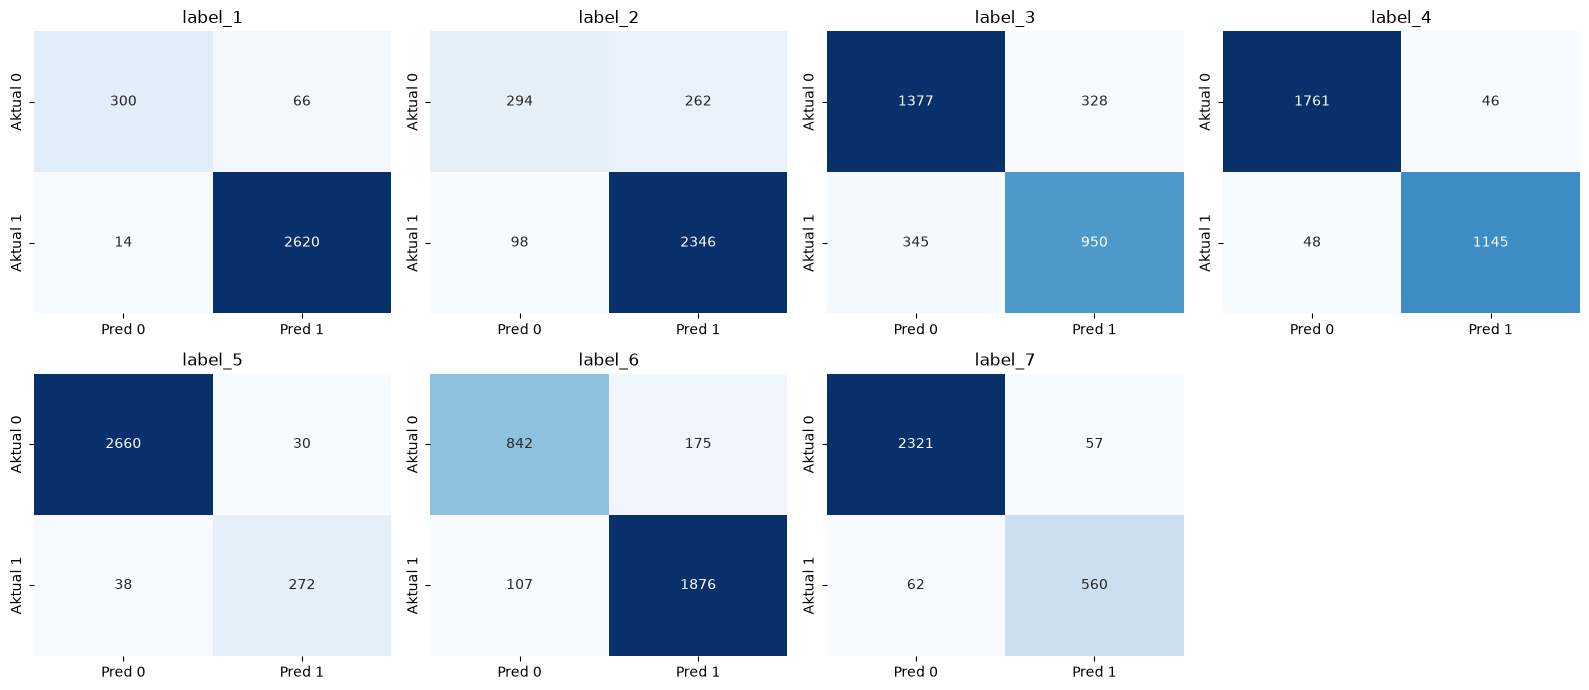

In [10]:
mcm = multilabel_confusion_matrix(Y_test.values, pred)
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, m, nama in zip(axes.ravel(), mcm, LABEL_COLS):
    sns.heatmap(m, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Pred 0", "Pred 1"], yticklabels=["Aktual 0", "Aktual 1"])
    ax.set_title(nama)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

In [12]:
def label_aktif(baris):
    aktif = [LABEL_COLS[i] for i, v in enumerate(baris) if v == 1]
    return ", ".join(aktif) if aktif else "(tidak ada)"

# Contoh prediksi pada 10 baris pertama data test
contoh = pd.DataFrame({
    "label_aktual": [label_aktif(r) for r in Y_test.values[:10]],
    "label_prediksi": [label_aktif(r) for r in pred[:10]],
    "semua_benar": (Y_test.values[:10] == pred[:10]).all(axis=1),
})
print("Model:", nama_terbaik)
display(contoh)

Model: Random Forest


,label_aktual,label_prediksi,semua_benar
0,"label_1, label_2, label_6","label_1, label_2, label_6",True
1,"label_1, label_2, label_3, label_4, label_5, l...","label_1, label_2, label_3, label_4, label_5, l...",True
2,label_1,"label_1, label_3",False
3,"label_1, label_2, label_6","label_1, label_2, label_6",True
4,"label_1, label_2, label_4","label_1, label_2, label_4, label_6",False
5,label_2,"label_2, label_6",False
6,"label_1, label_6, label_7","label_1, label_3, label_6, label_7",False
7,"label_1, label_3, label_4","label_1, label_2, label_3, label_4",False
8,"label_1, label_2, label_3, label_6","label_1, label_2, label_3, label_6",True
9,"label_1, label_2, label_3, label_4, label_6","label_1, label_2, label_4, label_6",False


,jumlah_baris,persen
label_yang_salah,,
0,1707,56.9
1,997,33.2
2,227,7.6
3,55,1.8
4,12,0.4
6,2,0.1


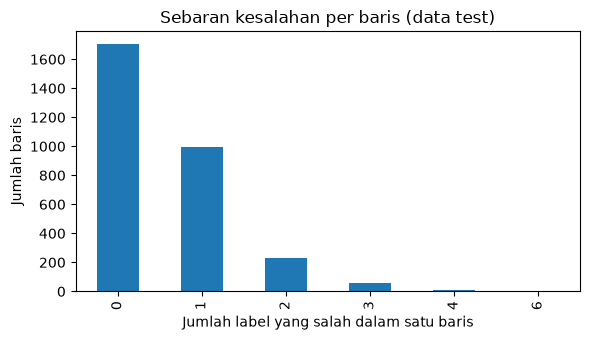

In [13]:
# Berapa label yang salah dalam satu baris?
jumlah_salah = (Y_test.values != pred).sum(axis=1)
dist = pd.Series(jumlah_salah).value_counts().sort_index()

tabel = dist.to_frame("jumlah_baris")
tabel["persen"] = (dist / len(Y_test) * 100).round(1)
tabel.index.name = "label_yang_salah"
display(tabel)

plt.figure(figsize=(6, 3.5))
dist.plot(kind="bar")
plt.xlabel("Jumlah label yang salah dalam satu baris")
plt.ylabel("Jumlah baris")
plt.title("Sebaran kesalahan per baris (data test)")
plt.tight_layout()
plt.show()

,persen_salah
label_3,22.4
label_2,12.0
label_6,9.4
label_7,4.0
label_4,3.1
label_1,2.7
label_5,2.3


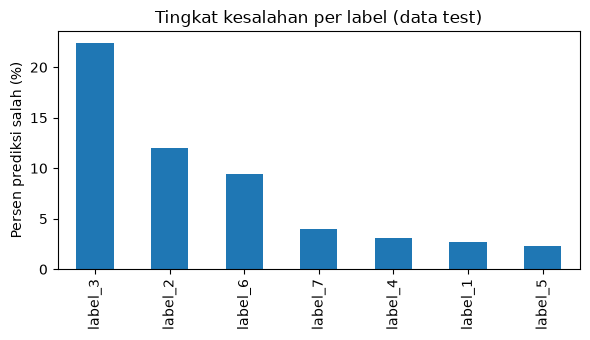

,baris_test,label_aktual,label_prediksi,label_yang_salah
0,1431,label_1,"label_1, label_2, label_3, label_4, label_5, l...",6
1,1675,"label_2, label_3, label_4, label_5, label_6, l...","label_1, label_2",6
2,531,"label_1, label_2, label_3, label_4, label_5, l...","label_1, label_3, label_6",4
3,1246,"label_1, label_3, label_6, label_7","label_2, label_6",4
4,2206,"label_3, label_6","label_1, label_2, label_6, label_7",4


In [14]:
# Label mana yang paling sering salah?
tingkat_salah = pd.Series((Y_test.values != pred).mean(axis=0), index=LABEL_COLS)
tingkat_salah = tingkat_salah.sort_values(ascending=False)
display((tingkat_salah * 100).round(1).to_frame("persen_salah"))

plt.figure(figsize=(6, 3.5))
(tingkat_salah * 100).plot(kind="bar")
plt.ylabel("Persen prediksi salah (%)")
plt.title("Tingkat kesalahan per label (data test)")
plt.tight_layout()
plt.show()

# Baris dengan kesalahan terbanyak, untuk diperiksa manual
terburuk = np.argsort(-jumlah_salah)[:5]
display(pd.DataFrame({
    "baris_test": terburuk,
    "label_aktual": [label_aktif(Y_test.values[i]) for i in terburuk],
    "label_prediksi": [label_aktif(pred[i]) for i in terburuk],
    "label_yang_salah": jumlah_salah[terburuk],
}))

# README: Dataset Zipcode (Klasifikasi Multilabel)

## Ringkasan dataset

| Item | Keterangan |
|---|---|
| File | `zipcode_train.csv`, `zipcode_test.csv` |
| Jumlah data | Train 3.000 baris, test 3.000 baris |
| Kolom | 17 kolom per file, **tanpa header** dan tanpa dokumentasi |
| Label (hasil inferensi) | Kolom 0-6: 7 kolom biner 0/1, diberi nama `label_1` sampai `label_7` |
| Fitur (hasil inferensi) | Kolom 7-16: 10 kolom, diberi nama `fitur_1` sampai `fitur_10` |
| Missing value | Tidak ada |
| Duplikat | Tidak ada di train, 7 baris di test |

Karena file tidak punya header, baris pertama harus dibaca sebagai data (`header=None`). Kalau tidak, satu baris data hilang.

**Penetapan kolom label adalah inferensi dari data, bukan informasi dari file.** Dasarnya: kolom 0-6 bernilai 0/1 dan banyak yang saling berkorelasi, serta masing-masing dapat diprediksi dari kolom 7-15 dengan ROC-AUC 0,84-0,99. Kalau sumber dataset memberi tahu peran kolom yang berbeda, penetapan ini perlu diubah.

## Mengapa ini termasuk klasifikasi multilabel

1. **Pembelajaran terawasi (supervised).** Train dan test sama-sama berisi kolom label, sehingga model dilatih di train dan diuji di test.
2. **Targetnya berupa beberapa kolom biner.** Ada 7 label, masing-masing bernilai 0 atau 1. Targetnya bukan satu kolom kelas, melainkan vektor 7 angka 0/1.
3. **Satu baris boleh punya beberapa label sekaligus.** Rata-rata ada 3,53 label aktif per baris, dan 94,5% baris punya lebih dari satu label aktif.
4. **Label tidak saling lepas.** Inilah pembeda utama dari klasifikasi multikelas. Pada multikelas, satu data hanya masuk ke tepat satu kelas. Di sini, banyak label aktif bersamaan, dengan 61 kombinasi label berbeda di train.
5. **Keluaran model berupa himpunan label.** Model memprediksi label mana saja yang aktif untuk setiap baris.

| Label | Jumlah positif (train) | Persentase train | Persentase test |
|---|---|---|---|
| label_1 | 2.661 | 88,7% | 87,8% |
| label_2 | 2.394 | 79,8% | 81,5% |
| label_6 | 2.000 | 66,7% | 66,1% |
| label_3 | 1.335 | 44,5% | 43,2% |
| label_4 | 1.206 | 40,2% | 39,8% |
| label_7 | 658 | 21,9% | 20,7% |
| label_5 | 343 | 11,4% | 10,3% |

Label cardinality adalah 3,53 dan label density 0,505. Hanya 3 baris train yang tanpa label aktif.

## Karakteristik penting

- **Fitur:** `fitur_1` hanya bernilai 0, 1, atau 2, sedangkan `fitur_2` sampai `fitur_9` numerik kontinu.
- **Kolom `fitur_10`** berisi angka 1-10 yang berulang secara urut mengikuti nomor baris, baik di train maupun di test. Kolom ini ternyata ikut membantu prediksi, sehingga disertakan sebagai fitur.
- **Distribusi train dan test hampir sama.** Ada 57 kombinasi label di test, dan 4 di antaranya tidak muncul di train.
- **Pembagian data:** train dan test sudah tersedia terpisah. Perbandingan model memakai `KFold` biasa pada train, karena `StratifiedKFold` tidak mendukung target multilabel.

## Hasil baseline (fitur kolom 7-16, dilatih di train, diuji di test)

| Model | Subset accuracy | Hamming loss | F1 micro | F1 macro |
|---|---|---|---|---|
| Random Forest | 0,569 | 0,080 | 0,921 | 0,905 |
| Gradient Boosting | 0,557 | 0,083 | 0,918 | 0,903 |
| KNN | 0,528 | 0,096 | 0,905 | 0,888 |
| Logistic Regression (balanced) | 0,318 | 0,171 | 0,825 | 0,799 |

Pembanding menebak semua 0 memberi hamming loss 0,505. **Subset accuracy** menuntut ketujuh label tepat sekaligus, sehingga nilainya jauh lebih rendah daripada F1. Model berbasis pohon jauh mengungguli model linear, yang menandakan hubungan antara fitur dan label tidak linear. Label yang paling sulit adalah `label_3` dan `label_2` (ROC-AUC sekitar 0,83-0,84 pada Random Forest tanpa `fitur_10`).

## LINK DATASET

Sythetic MultiLabel Classification Dataset https://www.kaggle.com/datasets/kylegraupe/zipcode-classifica